In [1]:
import time
import joblib
import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [2]:
CFG = dict(
    data_path="News_Category_Dataset_v3.json",
    merge_categories=False,  
    C=0.3,          
    class_weight="sqrt",    # "none" | "balanced" | "sqrt"
    epochs=25,
    batch_size=2048,
    lr=0.02,
    patience=4,                 # early stopping по val macro-F1
    w_head=1.0, w_desc=1.0, w_auth=1.0,
    seed=42,
)
torch.manual_seed(CFG["seed"])
np.random.seed(CFG["seed"])

In [3]:
df = pd.read_json(CFG["data_path"], lines=True)
for c in ("headline", "short_description", "authors"):
    df[c] = df[c].fillna("").astype(str).str.strip()

df = df[df["headline"] != ""]
df = df.drop_duplicates(subset=["headline", "short_description"]).reset_index(drop=True)

if CFG["merge_categories"]:
    merge = {
        "THE WORLDPOST": "WORLD NEWS", "WORLDPOST": "WORLD NEWS",
        "ARTS": "ARTS & CULTURE", "CULTURE & ARTS": "ARTS & CULTURE",
        "PARENTS": "PARENTING", "STYLE": "STYLE & BEAUTY", "GREEN": "ENVIRONMENT",
        "TASTE": "FOOD & DRINK", "COLLEGE": "EDUCATION", "HEALTHY LIVING": "WELLNESS",
    }
    df["category"] = df["category"].replace(merge)

le = LabelEncoder()
y = le.fit_transform(df["category"])
n_classes = len(le.classes_)
print(f"Документов: {len(df)}, классов: {n_classes}")
print("Доля строк с пустым authors:", (df["authors"] == "").mean().round(3))

Документов: 209036, классов: 42
Доля строк с пустым authors: 0.179


## Разбиение train / val / test (80 / 10 / 10, стратифицированное)

In [4]:
idx = np.arange(len(df))
idx_tr, idx_tmp = train_test_split(idx, test_size=0.2, stratify=y, random_state=CFG["seed"])
idx_val, idx_te = train_test_split(idx_tmp, test_size=0.5, stratify=y[idx_tmp], random_state=CFG["seed"])
df_tr, df_val, df_te = df.iloc[idx_tr], df.iloc[idx_val], df.iloc[idx_te]
y_tr, y_val, y_te = y[idx_tr], y[idx_val], y[idx_te]
print(len(df_tr), len(df_val), len(df_te))

167228 20904 20904


## Векторизация

Три независимых TF-IDF, обучаются **только на train**. Авторы: каждый автор из списка через запятую — один токен.

In [5]:
def split_authors(s):
    return [a.strip().lower() for a in s.split(",") if a.strip()]

vec_head = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2, max_df=0.9,
                           strip_accents="unicode", dtype=np.float32)
vec_desc = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2, max_df=0.9,
                           strip_accents="unicode", dtype=np.float32)
vec_auth = TfidfVectorizer(tokenizer=split_authors, token_pattern=None, lowercase=False,
                           min_df=2, dtype=np.float32)

def stack(d, fit=False):
    f = (lambda v, x: v.fit_transform(x)) if fit else (lambda v, x: v.transform(x))
    return sp.hstack([
        CFG["w_head"] * f(vec_head, d["headline"]),
        CFG["w_desc"] * f(vec_desc, d["short_description"]),
        CFG["w_auth"] * f(vec_auth, d["authors"]),
    ], format="csr", dtype=np.float32)

t0 = time.time()
X_tr = stack(df_tr, fit=True)
X_val, X_te = stack(df_val), stack(df_te)
print(f"Векторизация: {time.time() - t0:.1f}s")
print("Словари: headline={}, description={}, authors={}".format(
    len(vec_head.vocabulary_), len(vec_desc.vocabulary_), len(vec_auth.vocabulary_)))
print("X_train:", X_tr.shape)

Векторизация: 88.4s
Словари: headline=173762, description=298965, authors=20475
X_train: (167228, 493202)


In [6]:
def to_torch_sparse(X, device):
    coo = X.tocoo()
    i = torch.from_numpy(np.vstack([coo.row, coo.col]).astype(np.int64))
    v = torch.from_numpy(coo.data)
    return torch.sparse_coo_tensor(i, v, coo.shape, device=device).coalesce()


class LinearSVM(torch.nn.Module):
    def __init__(self, n_features, n_classes):
        super().__init__()
        self.W = torch.nn.Parameter(torch.zeros(n_features, n_classes))
        self.b = torch.nn.Parameter(torch.zeros(n_classes))

    def forward(self, X_sparse):
        return torch.sparse.mm(X_sparse, self.W) + self.b


def class_weights(y, n_classes, mode):
    if mode == "none":
        return np.ones(n_classes, dtype=np.float32)
    counts = np.bincount(y, minlength=n_classes).astype(np.float64)
    w = counts.sum() / (n_classes * np.maximum(counts, 1))   # как sklearn "balanced"
    if mode == "sqrt":
        w = np.sqrt(w)
    return w.astype(np.float32)


@torch.no_grad()
def predict_scores(model, X, bs=8192):
    model.eval()
    out = [model(to_torch_sparse(X[i:i + bs], device)).cpu() for i in range(0, X.shape[0], bs)]
    return torch.cat(out).numpy()

## Обучение

In [7]:
def train_svm(X_train, y_train, X_val, y_val, cfg):
    n, d = X_train.shape
    model = LinearSVM(d, n_classes).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"])

    cw = torch.tensor(class_weights(y_train, n_classes, cfg["class_weight"]), device=device)
    y_train_t = torch.from_numpy(y_train).to(device)
    lam = 1.0 / (cfg["C"] * n)

    history, best_f1, best_state, bad = [], -1.0, None, 0
    rng = np.random.default_rng(cfg["seed"])

    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        t0 = time.time()
        perm = rng.permutation(n)
        Xp = X_train[perm]
        yp = y_train_t[torch.from_numpy(perm).to(device)]
        total = 0.0

        for i in range(0, n, cfg["batch_size"]):
            xb = to_torch_sparse(Xp[i:i + cfg["batch_size"]], device)
            yb = yp[i:i + cfg["batch_size"]]

            scores = model(xb)
            target = -torch.ones_like(scores)          # OvR: +1 для своего класса, -1 для остальных
            target.scatter_(1, yb[:, None], 1.0)
            hinge = torch.clamp(1.0 - target * scores, min=0.0) ** 2
            loss_data = (hinge.sum(1) * cw[yb]).mean()
            loss = loss_data + 0.5 * lam * (model.W ** 2).sum()

            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            total += loss_data.item() * len(yb)
        sched.step()

        pred = predict_scores(model, X_val).argmax(1)
        f1, acc = f1_score(y_val, pred, average="macro"), accuracy_score(y_val, pred)
        history.append(dict(epoch=epoch, loss=total / n, val_acc=acc, val_f1=f1))
        print(f"epoch {epoch:02d} | loss {total / n:.4f} | val acc {acc:.4f} | "
              f"val macro-F1 {f1:.4f} | {time.time() - t0:.1f}s")

        if f1 > best_f1:
            best_f1, bad = f1, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= cfg["patience"]:
                print("Early stopping")
                break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)


t0 = time.time()
model, history = train_svm(X_tr, y_tr, X_val, y_val, CFG)
print(f"Обучение: {time.time() - t0:.1f}s")

epoch 01 | loss 4.2432 | val acc 0.7445 | val macro-F1 0.6689 | 8.8s
epoch 02 | loss 1.0219 | val acc 0.7564 | val macro-F1 0.6851 | 6.2s
epoch 03 | loss 0.7614 | val acc 0.7551 | val macro-F1 0.6834 | 8.5s
epoch 04 | loss 0.6743 | val acc 0.7579 | val macro-F1 0.6876 | 6.1s
epoch 05 | loss 0.6307 | val acc 0.7573 | val macro-F1 0.6870 | 6.5s
epoch 06 | loss 0.6055 | val acc 0.7575 | val macro-F1 0.6859 | 7.4s
epoch 07 | loss 0.5873 | val acc 0.7590 | val macro-F1 0.6880 | 8.5s
epoch 08 | loss 0.5746 | val acc 0.7598 | val macro-F1 0.6890 | 8.2s
epoch 09 | loss 0.5583 | val acc 0.7595 | val macro-F1 0.6892 | 7.4s
epoch 10 | loss 0.5458 | val acc 0.7596 | val macro-F1 0.6895 | 9.1s
epoch 11 | loss 0.5322 | val acc 0.7605 | val macro-F1 0.6903 | 9.0s
epoch 12 | loss 0.5165 | val acc 0.7603 | val macro-F1 0.6901 | 9.0s
epoch 13 | loss 0.5033 | val acc 0.7623 | val macro-F1 0.6927 | 9.8s
epoch 14 | loss 0.4894 | val acc 0.7620 | val macro-F1 0.6934 | 9.8s
epoch 15 | loss 0.4752 | val acc 0

## Кривые обучения

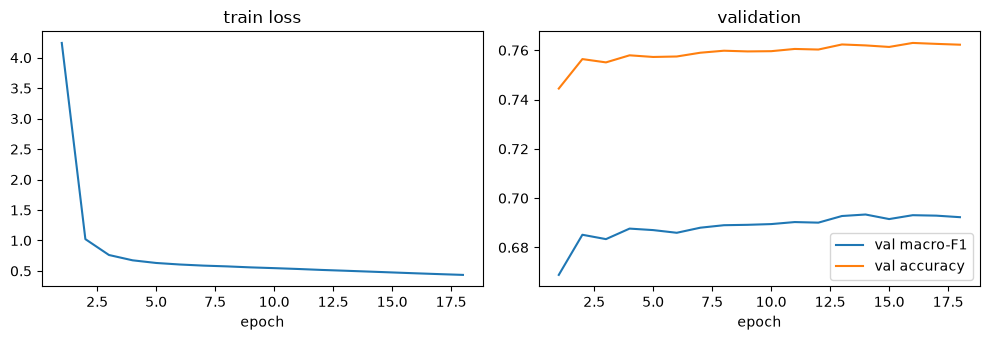

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history["epoch"], history["loss"]); ax[0].set_title("train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(history["epoch"], history["val_f1"], label="val macro-F1")
ax[1].plot(history["epoch"], history["val_acc"], label="val accuracy")
ax[1].set_title("validation"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## Оценка на test

In [9]:
pred_te = predict_scores(model, X_te).argmax(1)
print(f"accuracy    : {accuracy_score(y_te, pred_te):.4f}")
print(f"macro F1    : {f1_score(y_te, pred_te, average='macro'):.4f}")
print(f"weighted F1 : {f1_score(y_te, pred_te, average='weighted'):.4f}")
print(classification_report(y_te, pred_te, target_names=le.classes_, digits=3))

accuracy    : 0.7559
macro F1    : 0.6822
weighted F1 : 0.7548
                precision    recall  f1-score   support

          ARTS      0.634     0.675     0.654       151
ARTS & CULTURE      0.667     0.556     0.607       133
  BLACK VOICES      0.688     0.627     0.656       458
      BUSINESS      0.665     0.659     0.662       599
       COLLEGE      0.553     0.640     0.593       114
        COMEDY      0.695     0.716     0.706       539
         CRIME      0.553     0.657     0.601       356
CULTURE & ARTS      0.775     0.514     0.618       107
       DIVORCE      0.840     0.840     0.840       343
     EDUCATION      0.558     0.569     0.563       102
 ENTERTAINMENT      0.808     0.795     0.802      1736
   ENVIRONMENT      0.598     0.528     0.561       144
         FIFTY      0.767     0.729     0.747       140
  FOOD & DRINK      0.835     0.860     0.847       634
     GOOD NEWS      0.625     0.576     0.599       139
         GREEN      0.510     0.487     

In [10]:
has_author = (df_te["authors"].values != "")
print(f"Доля строк с автором в test: {has_author.mean():.3f}")
for name, m in [("с автором", has_author), ("без автора", ~has_author)]:
    if m.sum() == 0:
        continue
    print(f"{name:11s} n={m.sum():6d} | acc {accuracy_score(y_te[m], pred_te[m]):.4f} "
          f"| macro-F1 {f1_score(y_te[m], pred_te[m], average='macro'):.4f}")

Доля строк с автором в test: 0.820
с автором   n= 17133 | acc 0.7638 | macro-F1 0.6907
без автора  n=  3771 | acc 0.7200 | macro-F1 0.5494


## Самые слабые классы

In [11]:
from sklearn.metrics import precision_recall_fscore_support
p, r, f, s = precision_recall_fscore_support(y_te, pred_te, labels=range(n_classes), zero_division=0)
per_class = pd.DataFrame(dict(category=le.classes_, precision=p, recall=r, f1=f, support=s))
per_class.sort_values("f1").head(10)

,category,precision,recall,f1,support
35,U.S. NEWS,0.398058,0.297101,0.340249,138
15,GREEN,0.510040,0.486590,0.498039,261
18,IMPACT,0.518072,0.494253,0.505882,348
40,WORLD NEWS,0.572438,0.492401,0.529412,329
37,WEIRD NEWS,0.497041,0.606498,0.546341,277
11,ENVIRONMENT,0.598425,0.527778,0.560886,144
9,EDUCATION,0.557692,0.568627,0.563107,102
39,WOMEN,0.572650,0.575931,0.574286,349
33,THE WORLDPOST,0.589888,0.572207,0.580913,367
4,COLLEGE,0.553030,0.640351,0.593496,114
